In [96]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, roc_curve, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

In [70]:
train = pd.read_csv("/train.csv")
test = pd.read_csv("/test_features.csv")

In [103]:
print("Train shape:",train.shape)
print("Test shape:", test.shape)
train.head()

Train shape: (800, 19)
Test shape: (200, 18)


,patient_id,Возраст,Пол_мужской,ИМТ,Окружность_талии_см,САД_мм_рт_ст,ДАД_мм_рт_ст,Пульсовое_давление,Глюкоза_натощак_ммоль_л,HbA1c_%,ЛПНП_ммоль_л,ЛПВП_ммоль_л,Триглицериды_ммоль_л,СКФ_мл_мин,Курение,Физическая_активность_мин_нед,prediction,Статус_глюкозы,Доклинический_риск
0,1,41,1,24.24,81.04,113.19,62.54,50.65,4.595,4.65,NaN,NaN,1.379,115.52,0,165.8,0,0,0
1,4,53,0,19.84,73.44,119.75,71.59,48.15,4.431,5.08,2.268,2.022,1.467,93.39,0,248.1,0,0,0
2,5,53,1,24.28,82.06,127.07,70.34,56.73,4.997,5.04,2.459,1.325,0.967,88.41,0,230.5,0,0,0
3,6,60,1,25.19,91.89,116.98,82.00,34.98,5.491,5.00,3.700,0.722,1.505,91.06,1,132.5,1,0,0
4,7,59,1,24.45,84.07,129.12,82.70,46.42,6.456,4.80,3.960,1.406,2.274,89.74,1,177.4,1,2,0


подготовка данных для обучения модели

In [104]:
#Определение целевой переменной и идентификатора
TARGET = "prediction"
ID_COL = "patient_id"

DROP_COLS = [ID_COL, TARGET, "Статус_глюкозы", "Доклинический_риск"]

y = train[TARGET].values.astype(np.float32).reshape(-1, 1)

In [105]:
#Формирование единого набора признаков для train и test
X_train_df = train.drop(columns=[c for c in DROP_COLS if c in train.columns])
X_test_df  = test.drop(columns=[c for c in DROP_COLS if c in test.columns])

common = [c for c in X_train_df.columns if c in X_test_df.columns]
X_train_df = X_train_df[common]
X_test_df  = X_test_df[common]

print("Колонки-признаки:", X_train_df.columns.tolist())

Колонки-признаки: ['Возраст', 'Пол_мужской', 'ИМТ', 'Окружность_талии_см', 'САД_мм_рт_ст', 'ДАД_мм_рт_ст', 'Пульсовое_давление', 'Глюкоза_натощак_ммоль_л', 'HbA1c_%', 'ЛПНП_ммоль_л', 'ЛПВП_ммоль_л', 'Триглицериды_ммоль_л', 'СКФ_мл_мин', 'Курение', 'Физическая_активность_мин_нед']


In [106]:
#Преобразование признаков в числовой формат
X_train_df = X_train_df.apply(pd.to_numeric, errors="coerce")
X_test_df  = X_test_df.apply(pd.to_numeric, errors="coerce")

In [107]:
#Обработка пропущенных значений
medians = X_train_df.median()
X_train_df = X_train_df.fillna(medians).fillna(0.0)
X_test_df  = X_test_df.fillna(medians).fillna(0.0)

print("Пропусков в train:", X_train_df.isna().sum().sum())
print("Пропусков в test:", X_test_df.isna().sum().sum())

Пропусков в train: 0
Пропусков в test: 0


In [108]:
#Формирование итоговых массивов данных
X = X_train_df.values.astype(np.float32)
X_test_full = X_test_df.values.astype(np.float32)

print(f"Признаков: {X.shape[1]}, Объектов: {X.shape[0]}")
print(f"Доля класса 1: {y.mean():.3f}")

Признаков: 15, Объектов: 800
Доля класса 1: 0.181


подготовка данных для нейросети

In [109]:
#Разбиение на train/validation
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [110]:
#Нормализация признаков
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val   = scaler.transform(X_val)
X_test_full = scaler.transform(X_test_full)

In [111]:
#Преобразование данных в тензоры
X_train_t = torch.tensor(X_train, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.float32)

X_val_t   = torch.tensor(X_val, dtype=torch.float32)
y_val_t   = torch.tensor(y_val, dtype=torch.float32)

X_test_t  = torch.tensor(X_test_full, dtype=torch.float32)

In [112]:
#Формирование DataLoader
batch_size = 32
train_dataset = TensorDataset(X_train_t, y_train_t)
val_dataset   = TensorDataset(X_val_t, y_val_t)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader   = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

Построение FFN

In [127]:
#Опредедение модели FFN
class PatientFFN(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.fc1 = nn.Linear(input_dim, 64)
        self.fc2 = nn.Linear(64, 32)
        self.fc3 = nn.Linear(32, 1)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(0.2)

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.relu(self.fc2(x))
        x = self.fc3(x)
        return x

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = PatientFFN(X_train.shape[1]).to(device)

In [128]:
#Функция потерь и оптимизатор
pos_weight_value = (1 - y_train.mean()) / y_train.mean()
print(f"pos_weight = {pos_weight_value:.3f}")

pos_weight = torch.tensor([pos_weight_value], dtype=torch.float32).to(device)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = optim.Adam(model.parameters(), lr=0.001)

pos_weight = 4.517


In [129]:
#Обучение FFN
epochs = 100
train_losses, val_losses = [], []

for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    for X_batch, y_batch in train_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        optimizer.zero_grad()
        outputs = model(X_batch)
        loss = criterion(outputs, y_batch)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * X_batch.size(0)
    epoch_train_loss = running_loss / len(train_loader.dataset)
    train_losses.append(epoch_train_loss)
    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for X_batch, y_batch in val_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)
            val_loss += loss.item() * X_batch.size(0)
    epoch_val_loss = val_loss / len(val_loader.dataset)
    val_losses.append(epoch_val_loss)

    if (epoch + 1) % 20 == 0:
        print(f"Epoch {epoch+1}/{epochs} — Train Loss: {epoch_train_loss:.4f}, Val Loss: {epoch_val_loss:.4f}")

Epoch 20/100 — Train Loss: 0.2098, Val Loss: 0.3352
Epoch 40/100 — Train Loss: 0.1243, Val Loss: 0.4281
Epoch 60/100 — Train Loss: 0.0823, Val Loss: 0.5564
Epoch 80/100 — Train Loss: 0.0544, Val Loss: 0.6351
Epoch 100/100 — Train Loss: 0.0448, Val Loss: 0.6660


Оценка модели на валидационной выборке

In [131]:
model.eval()
y_pred_prob = []
y_true = []

with torch.no_grad():
    for X_batch, y_batch in val_loader:
        X_batch = X_batch.to(device)
        outputs = model(X_batch)
        probs = torch.sigmoid(outputs)
        y_pred_prob.extend(probs.cpu().numpy().flatten())
        y_true.extend(y_batch.numpy().flatten())

y_pred_prob = np.array(y_pred_prob)
y_true = np.array(y_true)
y_pred_class = (y_pred_prob >= 0.5).astype(int)

print("\n" + "-"*25)
print("Оценка на валидации:")
print("-"*25)
print(f"Accuracy:  {accuracy_score(y_true, y_pred_class):.4f}")
print(f"Precision: {precision_score(y_true, y_pred_class):.4f}")
print(f"Recall:    {recall_score(y_true, y_pred_class):.4f}")
print(f"F1-score:  {f1_score(y_true, y_pred_class):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_true, y_pred_prob):.4f}")
print("\nConfusion Matrix:")
print(confusion_matrix(y_true, y_pred_class))



-------------------------
Оценка на валидации:
-------------------------
Accuracy:  0.9375
Precision: 0.8276
Recall:    0.8276
F1-score:  0.8276
ROC-AUC:   0.9782

Confusion Matrix:
[[126   5]
 [  5  24]]


Предсказания для тестовой выборки

In [132]:
model.eval()
with torch.no_grad():
    test_outputs = model(X_test_t.to(device))
    test_probs = torch.sigmoid(test_outputs).cpu().numpy().flatten()

print("Распределение вероятностей:")
print(f"  Мин:    {test_probs.min():.3f}")
print(f"  Макс:   {test_probs.max():.3f}")
print(f"  Среднее:{test_probs.mean():.3f}")
print(f"  Медиана:{np.median(test_probs):.3f}")

threshold = 0.5
print(f"\nПорог: {threshold:.1f}")

test_preds = (test_probs >= threshold).astype(int)
print(f"Единиц после порога: {test_preds.sum()} из {len(test_preds)}")
print(f"Уникальные значения: {set(test_preds)}")

Распределение вероятностей:
  Мин:    0.000
  Макс:   1.000
  Среднее:0.181
  Медиана:0.000

Порог: 0.5
Единиц после порога: 38 из 200
Уникальные значения: {np.int64(0), np.int64(1)}


Формирование и сохранение результатов

In [133]:
import os
os.makedirs("outputs", exist_ok=True)

result = pd.DataFrame({
    "patient_id": test[ID_COL].values,
    "prediction": test_preds,
})
result.to_csv("outputs/task1_predictions.csv", index=False)

Визуализация

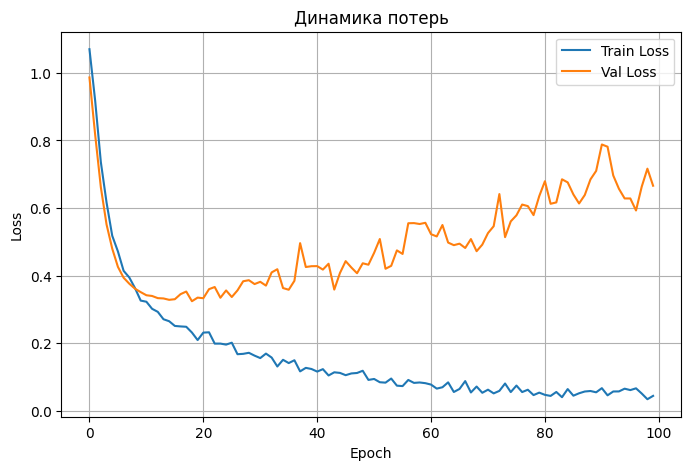

In [134]:
#Динамика функции потерь
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Val Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Динамика потерь')
plt.legend()
plt.grid(True)
plt.show()

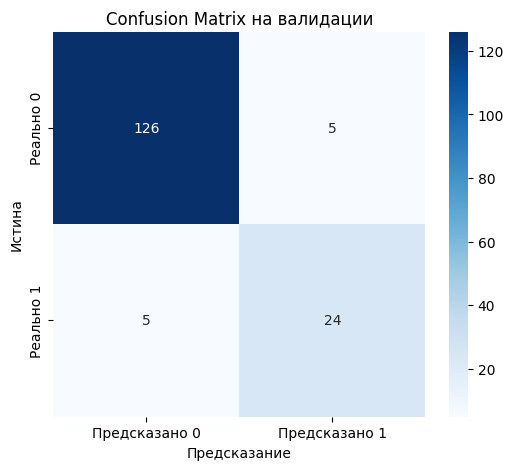

In [135]:
#Матрица ошибок
import seaborn as sns
cm = confusion_matrix(y_true, y_pred_class)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Предсказано 0', 'Предсказано 1'],
            yticklabels=['Реально 0', 'Реально 1'])
plt.ylabel('Истина')
plt.xlabel('Предсказание')
plt.title('Confusion Matrix на валидации')
plt.show()

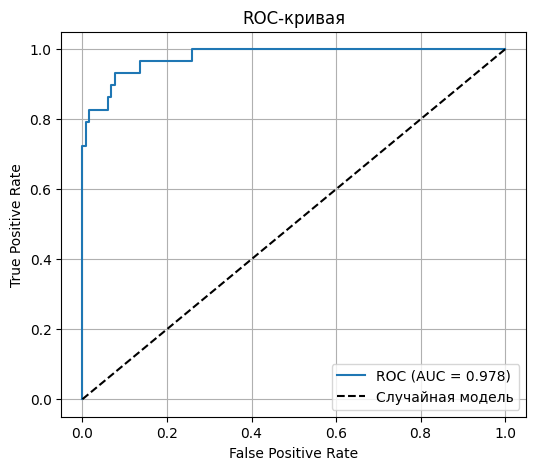

In [136]:
#ROC-кривая
fpr, tpr, _ = roc_curve(y_true, y_pred_prob)
auc = roc_auc_score(y_true, y_pred_prob)
plt.figure(figsize=(6, 5))

plt.plot(fpr, tpr, label=f'ROC (AUC = {auc:.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Случайная модель')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC-кривая')

plt.legend()
plt.grid(True)

plt.show()